# AgriSignal: which signals actually add information?

The first notebook found signals that move together with later price changes. Here I test the stricter question: does a signal help predict the next price change **beyond what past prices and the calendar already tell us**? A signal that only repeats information already in the price is no use to a model.

I also measure how accurate a few simple rules are at calling the direction of prices, so the model in the next step has a clear bar to beat.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller

sys.path.append(str(Path("..") / "src"))
from baselines import baseline_accuracy

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.width", 160)

features = pd.read_csv(Path("..") / "data" / "processed" / "features_monthly.csv")
SIGNALS = ["ndvi_anomaly", "rainfall_mm_anomaly", "tmax_c_anomaly", "stock_change",
           "msp_change", "food_inflation", "export_ban"]
features.groupby("crop")["month"].agg(["min", "max", "count"])

,min,max,count
crop,,,
paddy,2008-01,2026-09,225
wheat,2008-01,2026-09,225


## 1. The features use only the past

The features come from `src/build_features.py`. Each anomaly compares a month with the same calendar month in the **previous** five years (at least three), so nothing from the future leaks in, and a slow drift such as NDVI greening over the years is absorbed. The first three years are used up as history, so the data starts in January 2008.

## 2. Are the series stable?

Regression tests assume the series do not trend away forever. The Augmented Dickey-Fuller (ADF) test checks this: a p-value below 0.05 means the series is stable (stationary).

In [2]:
rows = []
for crop, data in features.groupby("crop"):
    for column in ["wpi", "price_change"] + SIGNALS:
        rows.append({"crop": crop, "series": column, "adf_p": adfuller(data[column], result_object=False)[1]})
adf = pd.DataFrame(rows).pivot(index="series", columns="crop", values="adf_p")
adf.round(3)

crop,paddy,wheat
series,,
export_ban,0.226,0.569
food_inflation,0.033,0.033
msp_change,0.062,0.001
ndvi_anomaly,0.000,0.000
price_change,0.012,0.000
rainfall_mm_anomaly,0.000,0.000
stock_change,0.022,0.136
tmax_c_anomaly,0.000,0.000
wpi,0.910,0.966


The price level (`wpi`) trends upward and is not stable, which is why everything below works with the monthly **price change** instead. The anomalies and price changes are stable. Wheat stock change and the export ban flag are not clearly stable: the ban is a policy regime that stays on for years, so its test results should be read with care.

## 3. The bar to beat: simple rules

Three rules call whether the price will be higher 1, 2 or 3 months later, using only outcomes already known at the time (from `src/baselines.py`). They are scored on 2012 onwards, the period the model will also be tested on.

- **always up**: whichever direction has been more common so far
- **calendar**: the direction most common for this calendar month so far
- **momentum**: the same direction the price moved over the last 1, 2 or 3 months

In [3]:
results = pd.concat([baseline_accuracy(features, months_ahead) for months_ahead in [1, 2, 3]])
baselines = results.pivot_table(index=["crop", "months_ahead"], columns="rule", values="accuracy")
baselines["best"] = baselines.idxmax(axis=1)
baselines["best_accuracy"] = baselines[["always_up", "calendar", "momentum"]].max(axis=1)
baselines.round(3)

rule                always_up  calendar  momentum       best  best_accuracy
crop  months_ahead                                                         
paddy 1                 0.642     0.676     0.676   calendar          0.676
      2                 0.714     0.714     0.657  always_up          0.714
      3                 0.753     0.741     0.644  always_up          0.753
wheat 1                 0.631     0.659     0.716   momentum          0.716
      2                 0.674     0.743     0.646   calendar          0.743
      3                 0.701     0.753     0.621   calendar          0.753

## 4. Granger causality tests

For each signal, crop and number of lags (1 to 3 months) I fit two regressions of this month's price change:

- **without the signal**: calendar month plus the last 1 to 3 price changes
- **with the signal**: the same, plus the signal's last 1 to 3 values

An F-test checks whether adding the signal improves the fit more than chance would. I also test the price's own past changes (momentum) against the calendar alone.

With 8 signals x 2 crops x 3 lags = 48 tests, a few would pass at 5% by luck, so the p-values are adjusted with the Benjamini-Hochberg method, which controls the share of false passes. A signal passes if its adjusted p-value is below 0.05.

In [4]:
def granger_test(data, signal, lags):
    """F-test p-value and summed coefficient for adding a signal's lags."""
    data = data.sort_values("month").reset_index(drop=True)
    X = pd.get_dummies(data["calendar_month"], prefix="month", drop_first=True).astype(float)
    for lag in range(1, lags + 1):
        X[f"price_lag{lag}"] = data["price_change"].shift(lag)
    tested = [f"price_lag{lag}" for lag in range(1, lags + 1)]
    if signal != "own_momentum":
        tested = [f"signal_lag{lag}" for lag in range(1, lags + 1)]
        for lag in range(1, lags + 1):
            X[f"signal_lag{lag}"] = data[signal].shift(lag)
    model_data = pd.concat([data["price_change"].rename("y"), X], axis=1).dropna()
    fit = sm.OLS(model_data["y"], sm.add_constant(model_data.drop(columns="y"))).fit()
    p_value = fit.f_test(", ".join(f"{name} = 0" for name in tested)).pvalue
    return float(p_value), fit.params[tested].sum(), len(model_data)


def run_tests(data_by_crop):
    rows = []
    for crop, data in data_by_crop:
        for signal in SIGNALS + ["own_momentum"]:
            for lags in [1, 2, 3]:
                p_value, effect, months = granger_test(data, signal, lags)
                rows.append({"crop": crop, "signal": signal, "lags": lags,
                             "p_value": p_value, "effect": effect, "months": months})
    return pd.DataFrame(rows)


granger = run_tests(features.groupby("crop"))
granger["p_adjusted"] = multipletests(granger["p_value"], method="fdr_bh")[1]
granger["passes"] = granger["p_adjusted"] < 0.05
granger.pivot_table(index=["crop", "signal"], columns="lags", values="p_adjusted").round(3)

lags                           1      2      3
crop  signal                                  
paddy export_ban           0.642  0.642  0.736
      food_inflation       0.642  0.834  0.892
      msp_change           0.103  0.059  0.175
      ndvi_anomaly         0.787  0.834  0.965
      own_momentum         0.000  0.000  0.000
      rainfall_mm_anomaly  0.728  0.659  0.642
      stock_change         0.642  0.451  0.642
      tmax_c_anomaly       0.489  0.642  0.642
wheat export_ban           0.999  0.966  0.999
      food_inflation       0.728  0.832  0.905
      msp_change           0.423  0.642  0.834
      ndvi_anomaly         0.002  0.012  0.039
      own_momentum         0.000  0.000  0.000
      rainfall_mm_anomaly  0.905  0.254  0.405
      stock_change         0.642  0.732  0.642
      tmax_c_anomaly       0.384  0.642  0.642

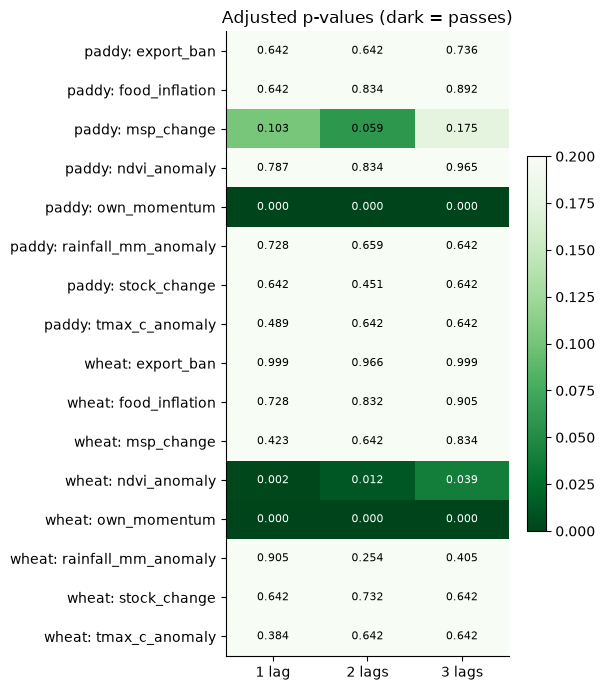

,crop,signal,lags,p_value,effect,months,p_adjusted,passes
21,paddy,own_momentum,1,0.0000,0.3790,224,0.0000,True
22,paddy,own_momentum,2,0.0000,0.3718,223,0.0000,True
23,paddy,own_momentum,3,0.0000,0.3955,222,0.0000,True
24,wheat,ndvi_anomaly,1,0.0003,-13.5675,224,0.0024,True
25,wheat,ndvi_anomaly,2,0.0020,-15.5886,223,0.0122,True
26,wheat,ndvi_anomaly,3,0.0074,-14.4388,222,0.0394,True
45,wheat,own_momentum,1,0.0000,0.3843,224,0.0000,True
46,wheat,own_momentum,2,0.0000,0.2833,223,0.0000,True
47,wheat,own_momentum,3,0.0000,0.3267,222,0.0000,True


In [5]:
table = granger.pivot_table(index=["crop", "signal"], columns="lags", values="p_adjusted")

fig, ax = plt.subplots(figsize=(6, 7))
image = ax.imshow(table.values, cmap="Greens_r", vmin=0, vmax=0.2, aspect="auto")
ax.set_xticks(range(3), ["1 lag", "2 lags", "3 lags"])
ax.set_yticks(range(len(table)), [f"{crop}: {signal}" for crop, signal in table.index])
for (row, column), value in pd.DataFrame(table.values).stack().items():
    ax.text(column, row, f"{value:.3f}", ha="center", va="center", fontsize=8,
            color="white" if value < 0.05 else "black")
ax.set_title("Adjusted p-values (dark = passes)")
fig.colorbar(image, ax=ax, shrink=0.6)
plt.tight_layout()
plt.show()

granger[granger["passes"]].round(4)

## 5. How big is the wheat NDVI effect?

The test says the effect is real; the coefficient says how big it is. The effect column is the sum of the signal's coefficients, in percentage points of monthly price change per unit of the signal.

In [6]:
wheat = features[features["crop"] == "wheat"]
typical_anomaly = wheat["ndvi_anomaly"].std()
for lags in [1, 2, 3]:
    effect = granger[(granger["crop"] == "wheat") & (granger["signal"] == "ndvi_anomaly")
                     & (granger["lags"] == lags)]["effect"].iloc[0]
    print(f"{lags} lags: a typical NDVI anomaly ({typical_anomaly:.3f}) moves next month's "
          f"price change by {effect * typical_anomaly:+.2f} percentage points")
print(f"For scale, the typical monthly wheat price change is {wheat['price_change'].std():.2f} points")

1 lags: a typical NDVI anomaly (0.028) moves next month's price change by -0.38 percentage points
2 lags: a typical NDVI anomaly (0.028) moves next month's price change by -0.44 percentage points
3 lags: a typical NDVI anomaly (0.028) moves next month's price change by -0.40 percentage points
For scale, the typical monthly wheat price change is 1.88 points


## 6. Paddy with true paddy prices only

Before April 2012 the paddy price is the rice index. Repeating the paddy tests from April 2012 (unadjusted p-values, since this is a check rather than the main test):

In [7]:
paddy_recent = features[(features["crop"] == "paddy") & (features["month"] >= "2012-04")]
check = run_tests([("paddy", paddy_recent)])
check.pivot_table(index="signal", columns="lags", values="p_value").round(3)

lags,1,2,3
signal,,,
export_ban,0.705,0.161,0.242
food_inflation,0.318,0.295,0.675
msp_change,0.167,0.216,0.495
ndvi_anomaly,0.619,0.580,0.414
own_momentum,0.000,0.000,0.000
rainfall_mm_anomaly,0.476,0.748,0.903
stock_change,0.865,0.399,0.608
tmax_c_anomaly,0.123,0.204,0.554


## What I found

**Satellite crop health adds real information for wheat.** The wheat NDVI anomaly passes the Granger test at 1, 2 and 3 lags even after adjusting for the 48 tests (adjusted p = 0.002, 0.012 and 0.039). The direction is the expected one: when the wheat states are greener than in recent years, the next price change is smaller. A typical NDVI anomaly shifts next month's wheat price change by about 0.4 percentage points, roughly a fifth of a typical monthly move.

**Past prices carry information for both crops.** A price that rose last month tends to rise again (momentum), which is why the momentum rule is a strong baseline for wheat.

**Everything else fails once past prices and the calendar are accounted for.**
- Paddy NDVI does not pass. With "normal" taken from the previous five years only, its earlier correlation mostly disappears, which fits the finding in the first notebook that much of it came from the slow greening trend.
- Paddy MSP change is the closest miss (adjusted p = 0.059 at 2 lags) and does not hold on the 2012 to 2026 paddy-only data.
- Heat, rainfall, stock changes, food inflation and export bans do not pass for either crop. Heat moved together with prices in the first notebook, but that information turns out to already be in past prices.

**The bar to beat is high.** Using only what was known at the time, simple rules already call the direction right 68% to 75% of the time on 2012 to 2026:

| Crop | 1 month ahead | 2 months ahead | 3 months ahead |
|---|---|---|---|
| Wheat | 71.6% (momentum) | 74.3% (calendar) | 75.3% (calendar) |
| Paddy | 67.6% (calendar) | 71.4% (always up) | 75.3% (always up) |

**What this means for the model.** The wheat model gets NDVI anomalies, past price changes and the calendar. For paddy, satellite data adds nothing measurable here, so the paddy model is mainly a test of whether momentum and the calendar can beat "always up". If the wheat model beats its baseline on unseen months and the paddy model does not, that is itself a clear result: crop health matters for wheat prices, while paddy prices are driven more by government buying.

**Caveats.**
- Granger causality means "helps predict", not "causes".
- These are linear tests on one month ahead. A model might still find use in a failed signal through non-linear effects or combinations, but with about 225 months there is little room for that.
- The export ban flag and wheat stock change are not clearly stationary, so their test results are less reliable.
